In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Function to calculate the Relative_Time_Minutes for each group
def calculate_relative_time(df_date):
    # Ensure the data is sorted by timestamp
    df_date = df_date.sort_values(by='Timestamp').reset_index(drop=True)
    
    # Calculate the minimum timestamp for each Condition group on this date
    # This resets the start time for each concentration's trajectory
    min_timestamps = df_date.groupby('Condition')['Timestamp'].transform('min')
    
    # Calculate the difference and convert to minutes
    time_diff = df_date['Timestamp'] - min_timestamps
    df_date['Relative_Time_Minutes'] = time_diff.dt.total_seconds() / 60
    
    return df_date

# --- Data Loading and Cleaning (Replication of previous successful steps) ---
df = pd.read_csv("data.csv", header=None, skiprows=4)
df_processed = df.iloc[:, [1, 4, 5, 8, 17]].copy()
df_processed.columns = ['Condition', 'Date', 'Time', 'A_i', 'Ratio']

df_processed.dropna(axis=0, how='all', inplace=True)
df_processed['Condition'] = df_processed['Condition'].ffill()
df_processed['Date'] = df_processed['Date'].ffill()
df_processed.dropna(subset=['A_i', 'Ratio'], inplace=True)
df_processed['Timestamp'] = pd.to_datetime(df_processed['Date'] + ' ' + df_processed['Time'])
df_processed['Ratio'] = df_processed['Ratio'].astype(str).str.replace('%', '').astype(float)

# Separate and apply the relative time function
df_20240417 = df_processed[df_processed['Date'] == '2024-04-17'].copy()
df_20240926 = df_processed[df_processed['Date'] == '2024-09-26'].copy()

df_20240417_relative = calculate_relative_time(df_20240417)
df_20240926_relative = calculate_relative_time(df_20240926)

# --- Plotting Function ---
CONDITION_ORDER = ['20 nM RV', '60 nM RV', '180nMRV']

def create_relative_time_plot(df, date, filename):
    plt.figure(figsize=(12, 7))
    
    # --------------------------------------------------------
    # FIX: Use hue_order to enforce consistent color mapping
    # --------------------------------------------------------
    sns.lineplot(data=df, 
                 x='Relative_Time_Minutes', 
                 y='Ratio', 
                 hue='Condition', 
                 hue_order=CONDITION_ORDER,  # <--- This guarantees consistent colors
                 marker='o', 
                 palette='deep', 
                 legend='full', 
                 sort=False)
    
    # Add Well ID (Ai) as annotations on the points
    for i in range(len(df)):
        plt.annotate(df['A_i'].iloc[i], 
                     (df['Relative_Time_Minutes'].iloc[i] + 0.1, df['Ratio'].iloc[i] + 0.5), 
                     fontsize=9, alpha=0.8)

    plt.title(f'Ratio Trajectories: Start Time Reset (T=0) for Date: {date}', fontsize=16)
    plt.xlabel('Relative Time from Group Start (Minutes)', fontsize=14)
    plt.ylabel('Ratio (%)', fontsize=14)
    
    plt.grid(axis='both', linestyle='--')
    plt.legend(title='RV Concentration', title_fontsize='12', fontsize='10')
    plt.tight_layout()
    plt.savefig(filename)
    plt.close()
    
# Create plots for each date
create_relative_time_plot(df_20240417_relative, '2024-04-17', 'plot_relative_time_20240417.png')
create_relative_time_plot(df_20240926_relative, '2024-09-26', 'plot_relative_time_20240926.png')

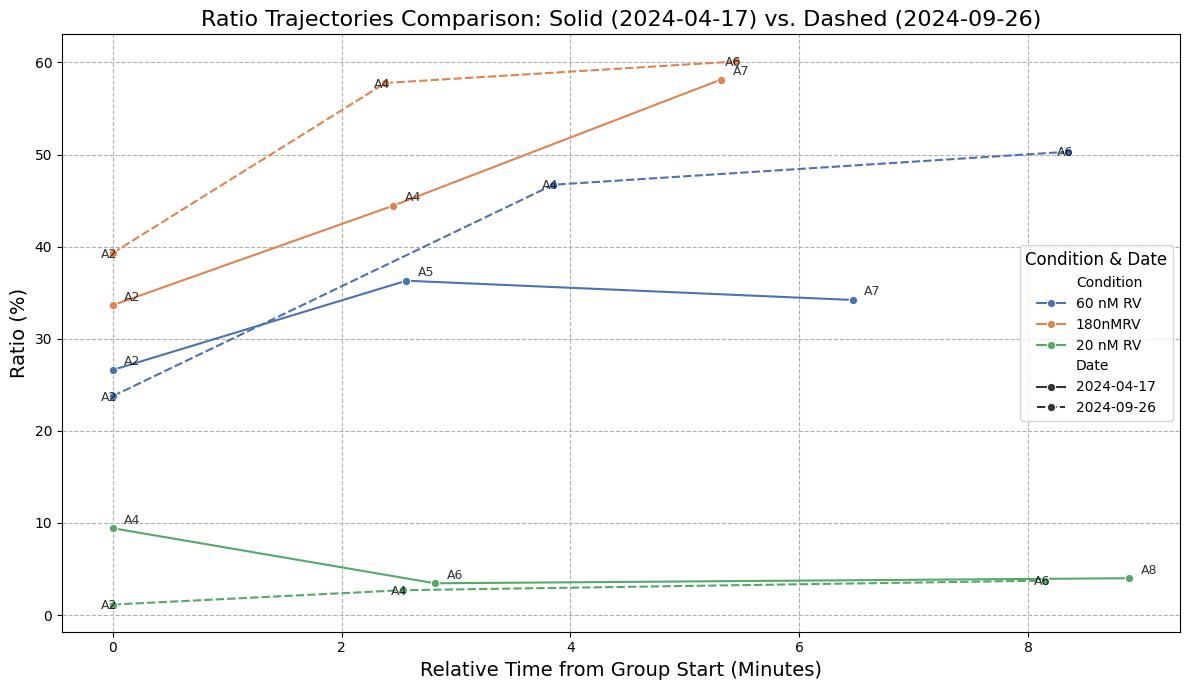

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Function to calculate the Relative_Time_Minutes for each group
def calculate_relative_time(df_date):
    # Ensure the data is sorted by timestamp
    df_date = df_date.sort_values(by='Timestamp').reset_index(drop=True)
    
    # Calculate the minimum timestamp for each Condition group on this date
    min_timestamps = df_date.groupby('Condition')['Timestamp'].transform('min')
    
    # Calculate the difference and convert to minutes
    time_diff = df_date['Timestamp'] - min_timestamps
    df_date['Relative_Time_Minutes'] = time_diff.dt.total_seconds() / 60
    
    return df_date

# --- Data Loading and Cleaning (All previous steps re-executed) ---
df = pd.read_csv("data.csv", header=None, skiprows=4)
df_processed = df.iloc[:, [1, 4, 5, 8, 17]].copy()
df_processed.columns = ['Condition', 'Date', 'Time', 'A_i', 'Ratio']

df_processed.dropna(axis=0, how='all', inplace=True)
df_processed['Condition'] = df_processed['Condition'].ffill()
df_processed['Date'] = df_processed['Date'].ffill()
df_processed.dropna(subset=['A_i', 'Ratio'], inplace=True)
df_processed['Timestamp'] = pd.to_datetime(df_processed['Date'] + ' ' + df_processed['Time'])
df_processed['Ratio'] = df_processed['Ratio'].astype(str).str.replace('%', '').astype(float)

# Separate and apply the relative time function
df_20240417 = df_processed[df_processed['Date'] == '2024-04-17'].copy()
df_20240926 = df_processed[df_processed['Date'] == '2024-09-26'].copy()

df_20240417_relative = calculate_relative_time(df_20240417)
df_20240926_relative = calculate_relative_time(df_20240926)

# Combine the dataframes
df_combined = pd.concat([df_20240417_relative, df_20240926_relative], ignore_index=True)

# --- Plotting ---
plt.figure(figsize=(12, 7))

# Plot the combined data, using 'Condition' for color (hue) and 'Date' for line style
sns.lineplot(data=df_combined, 
             x='Relative_Time_Minutes', 
             y='Ratio', 
             hue='Condition', 
             style='Date',
             marker='o',
             palette='deep', 
             legend='full', 
             sort=False)

# Add Well ID (A_i) as annotations, offsetting labels by date
for i in range(len(df_combined)):
    row = df_combined.iloc[i]
    x_pos, y_pos = row['Relative_Time_Minutes'], row['Ratio']
    a_i_label = row['A_i']
    
    # Use different offsets for solid (2024-04-17) and dashed (2024-09-26) lines
    if row['Date'] == '2024-04-17':
        # Offset slightly right and up for the solid line
        x_offset, y_offset = 0.1, 0.5
    else:
        # Offset slightly left and down for the dashed line
        x_offset, y_offset = -0.1, -0.5
    
    plt.annotate(a_i_label, 
                 (x_pos + x_offset, y_pos + y_offset), 
                 fontsize=9, alpha=0.8)

plt.title('Ratio Trajectories Comparison: Solid (2024-04-17) vs. Dashed (2024-09-26)', fontsize=16)
plt.xlabel('Relative Time from Group Start (Minutes)', fontsize=14)
plt.ylabel('Ratio (%)', fontsize=14)

plt.grid(axis='both', linestyle='--')
plt.legend(title='Condition & Date', title_fontsize='12', fontsize='10')
plt.tight_layout()

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Function to calculate the Relative_Time_Minutes for each group
def calculate_relative_time(df_date):
    # Ensure the data is sorted by timestamp
    df_date = df_date.sort_values(by='Timestamp').reset_index(drop=True)
    
    # Calculate the minimum timestamp for each Condition group on this date
    min_timestamps = df_date.groupby('Condition')['Timestamp'].transform('min')
    
    # Calculate the difference and convert to minutes
    time_diff = df_date['Timestamp'] - min_timestamps
    df_date['Relative_Time_Minutes'] = time_diff.dt.total_seconds() / 60
    
    return df_date

# Define a consistent order for the conditions and the palette
CONDITION_ORDER = ['20 nM RV', '60 nM RV', '180nMRV']
palette = sns.color_palette('deep')
color_map = {cond: palette[i % len(palette)] for i, cond in enumerate(CONDITION_ORDER)}

def create_sd_envelope_plot(df, date, filename):
    plt.figure(figsize=(12, 7))
    
    # Iterate through each condition to plot line and fill envelope
    for condition in CONDITION_ORDER:
        # Sort by time for correct plotting order
        df_cond = df[df['Condition'] == condition].sort_values(by='Relative_Time_Minutes')
        
        if df_cond.empty:
            continue

        color = color_map.get(condition, 'gray')
        label = condition
        
        x = df_cond['Relative_Time_Minutes']
        y = df_cond['Ratio_percent']
        y_sd = df_cond['SD_Ratio']
        
        # 1. Plot the main line
        plt.plot(x, y, label=label, color=color, marker='o', linestyle='-')
        
        # 2. Plot the error envelope (SD)
        plt.fill_between(x, y - y_sd, y + y_sd, alpha=0.15, color=color)
        
        # 3. Add Well ID (Ai) as annotations on the points
        for _, row in df_cond.iterrows():
            plt.annotate(row['A_i'], 
                         (row['Relative_Time_Minutes'] + 0.1, row['Ratio_percent'] + 0.5), 
                         fontsize=9, alpha=0.8)

    # Add title and labels
    plt.title(f'Ratio Trajectories with Binomial SD Envelope for Date: {date}', fontsize=16)
    plt.xlabel('Relative Time from Group Start (Minutes)', fontsize=14)
    plt.ylabel('Ratio (%)', fontsize=14)
    
    # Formatting
    plt.grid(axis='both', linestyle='--')
    plt.legend(title='RV Concentration', title_fontsize='12', fontsize='10')
    plt.tight_layout()
    #plt.savefig(filename)
    plt.savefig(filename, format='svg')
    plt.close()

# --- Data Loading and Cleaning ---
df = pd.read_csv("mydata.csv", header=None, skiprows=4)

# Select and rename columns using the corrected indices:
# Col 1: Condition, Col 4: Date, Col 5: Time, Col 8: A_i (Well ID), Col 9: n (No. of PL1), Col 15: k (Colocalized), Col 17: Ratio
df_processed = df.iloc[:, [0, 3, 4, 7, 8, 14, 16]].copy() 
df_processed.columns = ['Condition', 'Date', 'Time', 'A_i', 'n_PL1', 'k_Colocalized', 'Ratio_percent']

df_processed.dropna(axis=0, how='all', inplace=True)
df_processed['Condition'] = df_processed['Condition'].ffill()
df_processed['Date'] = df_processed['Date'].ffill()

df_processed['Ratio_percent'] = df_processed['Ratio_percent'].astype(str).str.replace('%', '').astype(float)
df_processed['n_PL1'] = pd.to_numeric(df_processed['n_PL1'], errors='coerce').fillna(0)
df_processed['k_Colocalized'] = pd.to_numeric(df_processed['k_Colocalized'], errors='coerce').fillna(0)

df_processed.dropna(subset=['A_i', 'Ratio_percent'], inplace=True) 

# Convert date format from DD/MM/YYYY to YYYY-MM-DD
df_processed['Timestamp'] = pd.to_datetime(df_processed['Date'] + ' ' + df_processed['Time'], format='%d/%m/%Y %H:%M:%S', errors='coerce')
df_processed['Date'] = df_processed['Timestamp'].dt.strftime('%Y-%m-%d')
df_processed.dropna(subset=['Timestamp'], inplace=True)


# --- SD Calculation ---
df_processed['p'] = df_processed['Ratio_percent'] / 100
df_processed['n'] = df_processed['n_PL1'] 

df_processed['Var_Ratio'] = np.where(
    df_processed['n'] > 0,
    100**2 * df_processed['p'] * (1 - df_processed['p']) / df_processed['n'],
    0.0
)
df_processed['SD_Ratio'] = np.sqrt(df_processed['Var_Ratio'])

# --- Time Calculation and Plotting ---
df_processed.dropna(subset=['Date', 'Time'], inplace=True)
df_processed['Timestamp'] = pd.to_datetime(df_processed['Date'] + ' ' + df_processed['Time'])

df_20240417 = df_processed[df_processed['Date'] == '2024-04-17'].copy()
df_20240926 = df_processed[df_processed['Date'] == '2024-09-26'].copy()

df_20240417_final = calculate_relative_time(df_20240417)
df_20240926_final = calculate_relative_time(df_20240926)

create_sd_envelope_plot(df_20240417_final, '2024-04-17', 'plot_sd_envelope_20240417.svg')
create_sd_envelope_plot(df_20240926_final, '2024-09-26', 'plot_sd_envelope_20240926.svg')

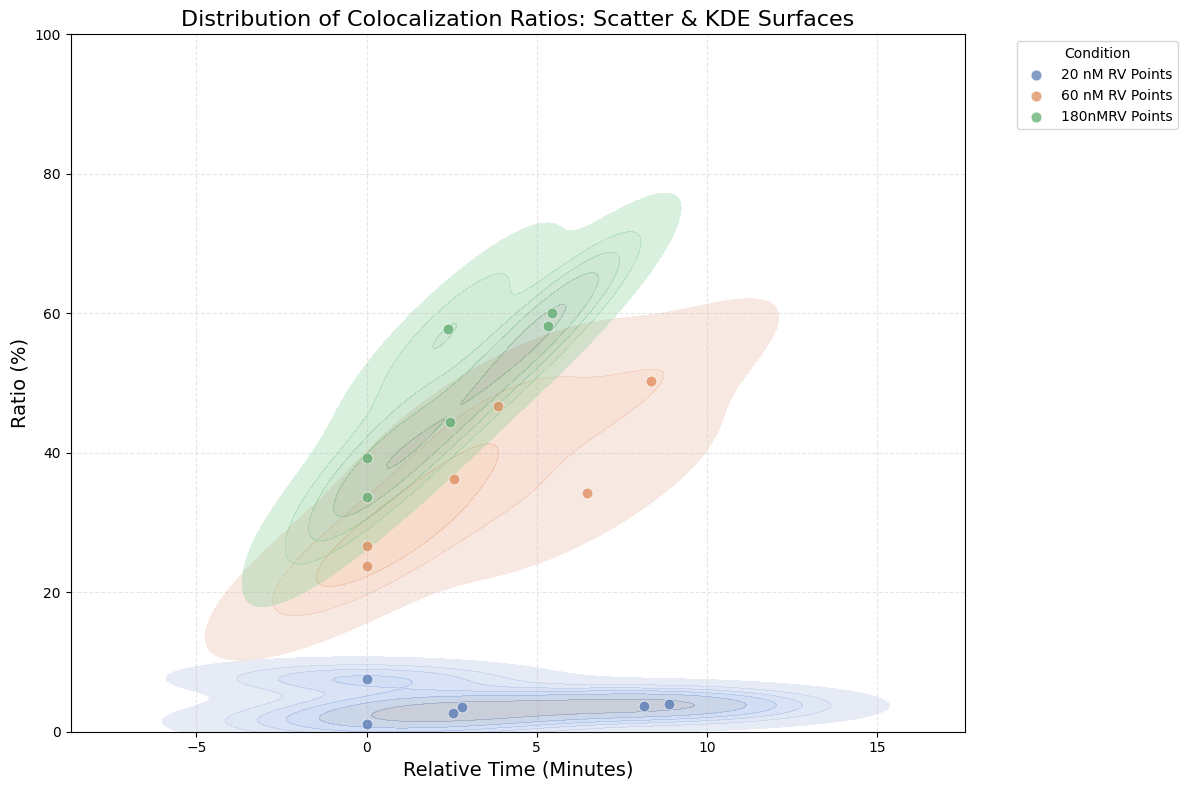

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Helper Function ---
def calculate_relative_time(df_date):
    df_date = df_date.sort_values(by='Timestamp').reset_index(drop=True)
    min_timestamps = df_date.groupby('Condition')['Timestamp'].transform('min')
    time_diff = df_date['Timestamp'] - min_timestamps
    df_date['Relative_Time_Minutes'] = time_diff.dt.total_seconds() / 60
    return df_date

# --- 2. New Plotting Function ---
def create_scatter_kde_plot(df_combined, filename):
    plt.figure(figsize=(12, 8))
    
    CONDITION_ORDER = ['20 nM RV', '60 nM RV', '180nMRV']
    # Using 'deep' palette for the KDE surfaces and scatter points
    palette = sns.color_palette('deep', len(CONDITION_ORDER))
    
    # 1. Overlay KDE Surfaces (Bivariate Density)
    # We plot this first so it stays in the background
    sns.kdeplot(
        data=df_combined,
        x='Relative_Time_Minutes',
        y='Ratio_percent',
        hue='Condition',
        hue_order=CONDITION_ORDER,
        fill=True,
        alpha=0.3,
        levels=7,
        thresh=0.05,
        palette='deep'
    )

    # 2. Add Scatter Points
    # We use different markers for different dates if you want to distinguish them visually
    for i, condition in enumerate(CONDITION_ORDER):
        df_cond = df_combined[df_combined['Condition'] == condition]
        if df_cond.empty: continue
        
        # Plot scatter points
        sns.scatterplot(
            data=df_cond,
            x='Relative_Time_Minutes',
            y='Ratio_percent',
            color=palette[i],
            s=60,
            alpha=0.7,
            edgecolor='w',
            label=f"{condition} Points"
        )

    plt.title('Distribution of Colocalization Ratios: Scatter & KDE Surfaces', fontsize=16)
    plt.xlabel('Relative Time (Minutes)', fontsize=14)
    plt.ylabel('Ratio (%)', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.ylim(0, 100)
    plt.legend(title='Condition', bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.savefig(filename, format='svg')
    plt.show()

# --- 3. Data Loading and Cleaning ---
df = pd.read_csv("mydata.csv", header=None, skiprows=4)
df_processed = df.iloc[:, [0, 3, 4, 7, 8, 14, 16]].copy() 
df_processed.columns = ['Condition', 'Date', 'Time', 'A_i', 'n_PL1', 'k_Colocalized', 'Ratio_percent']

# Data Cleaning
df_processed['Condition'] = df_processed['Condition'].ffill()
df_processed['Date'] = df_processed['Date'].ffill()
df_processed['Ratio_percent'] = df_processed['Ratio_percent'].astype(str).str.replace('%', '').astype(float)
df_processed.dropna(subset=['A_i', 'Ratio_percent', 'Date', 'Time'], inplace=True) 

# Timestamps
df_processed['Timestamp'] = pd.to_datetime(df_processed['Date'] + ' ' + df_processed['Time'], format='%d/%m/%Y %H:%M:%S', errors='coerce')
df_processed.dropna(subset=['Timestamp'], inplace=True)

# Split by date to calculate Relative Time per experiment
df_20240417 = calculate_relative_time(df_processed[df_processed['Timestamp'].dt.strftime('%Y-%m-%d') == '2024-04-17'].copy())
df_20240926 = calculate_relative_time(df_processed[df_processed['Timestamp'].dt.strftime('%Y-%m-%d') == '2024-09-26'].copy())

# --- 4. Combine and Plot ---
# Concatenate both dates so the KDE calculates density across the whole dataset
df_all_experiments = pd.concat([df_20240417, df_20240926])

create_scatter_kde_plot(df_all_experiments, 'combined_scatter_kde_plot_no_optimization.svg')

## Belifes

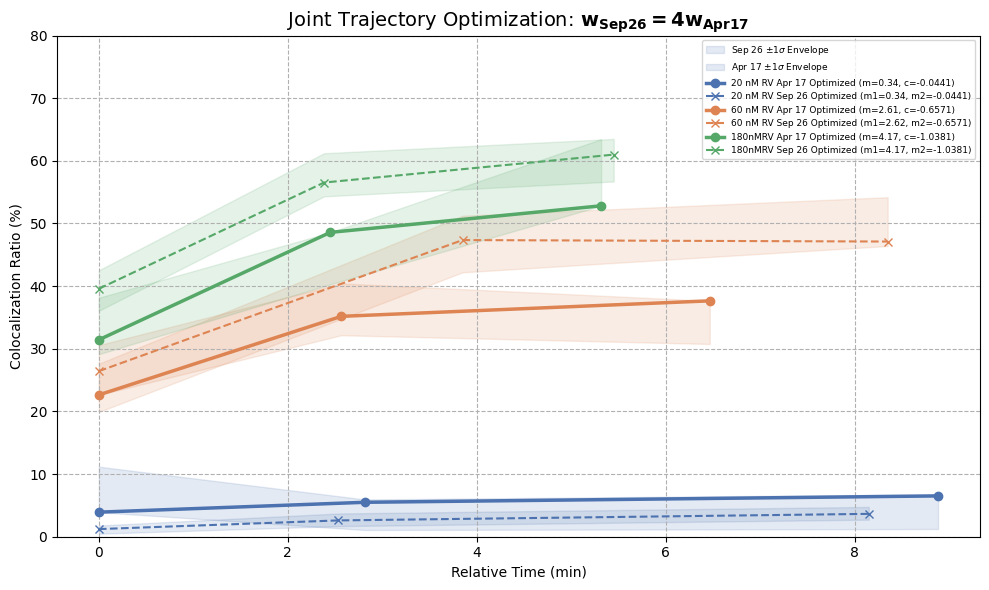

In [1]:
import pandas as pd
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns

belief_x = 4

# --- 1. Data Preparation Functions ---

def calculate_relative_time(df_date):
    """Calculates relative time in minutes for each condition."""
    df_date = df_date.sort_values(by='Timestamp').reset_index(drop=True)
    min_timestamps = df_date.groupby('Condition')['Timestamp'].transform('min')
    time_diff = df_date['Timestamp'] - min_timestamps
    df_date['Relative_Time_Minutes'] = time_diff.dt.total_seconds() / 60
    return df_date

# --- 2. Shape Descriptors Function ---

def get_shape_descriptors(t, y):
    """
    Calculates slope (mu) and curvature (kappa) based on a quadratic fit.
    t is centered to decouple the terms.
    y = kappa * t_centered^2 + mu * t_centered + intercept
    """
    if len(t) < 2: return 0.0, 0.0
    t_centered = t - np.mean(t)
    
    if len(t) == 2:
        # Linear fit for only two points: coeffs = [slope, intercept]
        coeffs = np.polyfit(t_centered, y, 1)
        return coeffs[0], 0.0
    else:
        # Quadratic fit: coeffs = [curvature (kappa), slope (mu), intercept]
        coeffs = np.polyfit(t_centered, y, 2)
        return coeffs[1], coeffs[0] # Return slope (mu), curvature (kappa)

# --- 3. Joint Objective Function (The Core Math with Equal Belief) ---

def joint_objective(Y_all, N_A17, t_A17, M_A17, SD_A17, t_S26, M_S26, SD_S26):
    """
    The Loss Function (L) to minimize.
    L = L_Shape + L_Dev_A17 + L_Dev_S26
    Weighting: w_A17 = 1.0, w_S26 = 1.0 (Equal Belief)
    """
    Y_A17 = Y_all[:N_A17]
    Y_S26 = Y_all[N_A17:]
    
    # 1. Shape Mismatch Penalty (L_Shape)
    slope_A17, curv_A17 = get_shape_descriptors(t_A17, Y_A17)
    slope_S26, curv_S26 = get_shape_descriptors(t_S26, Y_S26)
    
    # High fixed weights to prioritize trend matching
    W_SLOPE = 1000.0
    W_CURV = 100.0 * W_SLOPE
    
    L_Shape = W_SLOPE * (slope_A17 - slope_S26)**2 + W_CURV * (curv_A17 - curv_S26)**2
    
    # 2. Deviation from Mean Penalties (L_Dev)
    
    # L_Dev, A17 (w_A17 = 1.0)
    # Normalized Chi-squared distance from mean
    L_Dev_A17 = 1.0 * np.sum(((Y_A17 - M_A17) / SD_A17)**2)
    
    # L_Dev, S26 (w_S26 = 1.0 - Equal Belief)
    L_Dev_S26 = belief_x * np.sum(((Y_S26 - M_S26) / SD_S26)**2)
    
    total_loss = L_Shape + L_Dev_A17 + L_Dev_S26
    return total_loss

# --- 4. Optimization Execution Function ---

def joint_optimize_trajectories(df_A17, df_S26, condition):
    
    # Prepare Data and Bounds
    data_A17 = df_A17[df_A17['Condition'] == condition].sort_values('Relative_Time_Minutes')
    data_S26 = df_S26[df_S26['Condition'] == condition].sort_values('Relative_Time_Minutes')
    
    if data_A17.empty or data_S26.empty or len(data_A17) < 2 or len(data_S26) < 2:
        return None
    
    # Extract data (Apr 17)
    t_A17, M_A17, SD_A17 = data_A17[['Relative_Time_Minutes', 'Ratio_percent', 'SD_Ratio']].values.T
    L_A17 = M_A17 - SD_A17
    U_A17 = M_A17 + SD_A17
    
    # Extract data (Sep 26)
    t_S26, M_S26, SD_S26 = data_S26[['Relative_Time_Minutes', 'Ratio_percent', 'SD_Ratio']].values.T
    L_S26 = M_S26 - SD_S26
    U_S26 = M_S26 + SD_S26
    
    # Handle zero SD for normalization
    SD_A17 = np.where(SD_A17 == 0, 1e-6, SD_A17)
    SD_S26 = np.where(SD_S26 == 0, 1e-6, SD_S26)

    # Setup Optimization Variables and Bounds
    Y_initial = np.concatenate([M_A17, M_S26])
    
    bounds_A17 = list(zip(L_A17, U_A17))
    bounds_S26 = list(zip(L_S26, U_S26))
    bounds_all = bounds_A17 + bounds_S26
    
    N_A17 = len(M_A17)
    args = (N_A17, t_A17, M_A17, SD_A17, t_S26, M_S26, SD_S26)
    
    # Perform Optimization
    result = minimize(
        joint_objective, 
        Y_initial, 
        args=args, 
        method='L-BFGS-B', 
        bounds=bounds_all
    )
    
    # Process Results
    Y_opt_all = result.x
    Y_opt_A17 = Y_opt_all[:N_A17]
    Y_opt_S26 = Y_opt_all[N_A17:]
    
    slope_A17, curv_A17 = get_shape_descriptors(t_A17, Y_opt_A17)
    slope_S26, curv_S26 = get_shape_descriptors(t_S26, Y_opt_S26)
    
    return {
        't_A17': t_A17, 'Y_A17': Y_opt_A17, 'L_A17': L_A17, 'U_A17': U_A17, 
        't_S26': t_S26, 'Y_S26': Y_opt_S26, 'L_S26': L_S26, 'U_S26': U_S26,
        'slope_A17': slope_A17, 'curv_A17': curv_A17,
        'slope_S26': slope_S26, 'curv_S26': curv_S26,
        'success': result.success
    }

# --- 5. Main Execution and Plotting ---

# --- Data Loading and Cleaning ---
df = pd.read_csv("mydata.csv", header=None, skiprows=4)
df_processed = df.iloc[:, [0, 3, 4, 7, 8, 14, 16]].copy()  # Shifted indices
df_processed.columns = ['Condition', 'Date', 'Time', 'A_i', 'n_PL1', 'k_Colocalized', 'Ratio_percent']
df_processed.dropna(axis=0, how='all', inplace=True)
df_processed['Condition'] = df_processed['Condition'].ffill()
df_processed['Date'] = df_processed['Date'].ffill()

df_processed['Ratio_percent'] = df_processed['Ratio_percent'].astype(str).str.replace('%', '', regex=False).astype(float)
df_processed['n_PL1'] = pd.to_numeric(df_processed['n_PL1'], errors='coerce')
df_processed['k_Colocalized'] = pd.to_numeric(df_processed['k_Colocalized'], errors='coerce')
df_processed.dropna(subset=['A_i', 'Ratio_percent', 'Date', 'Time', 'n_PL1', 'k_Colocalized'], inplace=True)

# Convert date format from DD/MM/YYYY to YYYY-MM-DD
df_processed['Timestamp'] = pd.to_datetime(df_processed['Date'] + ' ' + df_processed['Time'], format='%d/%m/%Y %H:%M:%S', errors='coerce')
df_processed['Date'] = df_processed['Timestamp'].dt.strftime('%Y-%m-%d')
df_processed.dropna(subset=['Timestamp'], inplace=True)

# SD Calculation (Binomial assumption)
df_processed['p'] = df_processed['Ratio_percent'] / 100
df_processed['n'] = df_processed['n_PL1']
df_processed['Var_Ratio'] = np.where(
    df_processed['n'] > 0,
    100**2 * df_processed['p'] * (1 - df_processed['p']) / df_processed['n'],
    0.0
)
df_processed['SD_Ratio'] = np.sqrt(df_processed['Var_Ratio'])

# Split and Relative Time Calculation
df_20240417 = calculate_relative_time(df_processed[df_processed['Date'] == '2024-04-17'].copy())
df_20240926 = calculate_relative_time(df_processed[df_processed['Date'] == '2024-09-26'].copy())

# --- Execute Joint Optimization ---
conditions = ['20 nM RV', '60 nM RV', '180nMRV']
joint_results = {}

for cond in conditions:
    res = joint_optimize_trajectories(df_20240417, df_20240926, cond)
    if res:
        joint_results[cond] = res

# --- Plotting the Joint Optimization Results ---
fig, ax = plt.subplots(figsize=(10, 6))
colors = sns.color_palette('deep')
color_map = {cond: colors[i] for i, cond in enumerate(conditions)}

legend_A17_envelope_added = False
legend_S26_envelope_added = False

for cond in conditions:
    res = joint_results.get(cond)
    if not res or not res['success']: 
        continue
        
    col = color_map[cond]
    
    # 1. Plot September 26 Envelope (Gray Shaded Area)
    sep_26_env_label = "Sep 26 $\\pm 1\\sigma$ Envelope" if not legend_S26_envelope_added else "_nolegend_"
    ax.fill_between(res['t_S26'], res['L_S26'], res['U_S26'], color=col, alpha=0.15, 
                    label=sep_26_env_label)
    legend_S26_envelope_added = True
    
    # 2. Plot April 17 Envelope (Colored Shaded Area)
    apr_17_env_label = "Apr 17 $\\pm 1\\sigma$ Envelope" if not legend_A17_envelope_added else "_nolegend_"
    ax.fill_between(res['t_A17'], res['L_A17'], res['U_A17'], color=col, alpha=0.15, 
                    label=apr_17_env_label)
    legend_A17_envelope_added = True
    
    # 3. Plot April 17 Optimized Trajectory - Colored Solid
    ax.plot(res['t_A17'], res['Y_A17'], color=col, linestyle='-', linewidth=2.5, marker='o', 
            label=f"{cond} Apr 17 Optimized (m={res['slope_A17']:.2f}, c={res['curv_A17']:.4f})")
    
    # 4. Plot Sep 26 Optimized Trajectory - Black Dashed Line (reference)
    ax.plot(res['t_S26'], res['Y_S26'], color=col, linestyle='--', linewidth=1.5, marker='x', 
            label=f"{cond} Sep 26 Optimized (m1={res['slope_S26']:.2f}, m2={res['curv_S26']:.4f})")


ax.set_title(f"Joint Trajectory Optimization: $\\mathbf{{w_{{Sep 26}} = {belief_x if belief_x>1 else ""} w_{{Apr 17}}}}$", fontsize=14)
#ax.set_title("Joint Trajectory Optimization: Absolute Belief of experiment Sep26", fontsize=14)
ax.set_xlabel("Relative Time (min)")
ax.set_ylabel("Colocalization Ratio (%)")
ax.grid(True, linestyle='--')
ax.set_ylim(0, 80)
ax.legend(loc='upper right', fontsize=6.5)

plt.tight_layout()
plt.savefig(f'joint_optimized_trajectories_{belief_x}x_belief_exp_sep26.svg', format='svg')
#plt.savefig('joint_optimized_trajectories_Absolute_Belief_of_exp_Sep26.svg', format='svg')

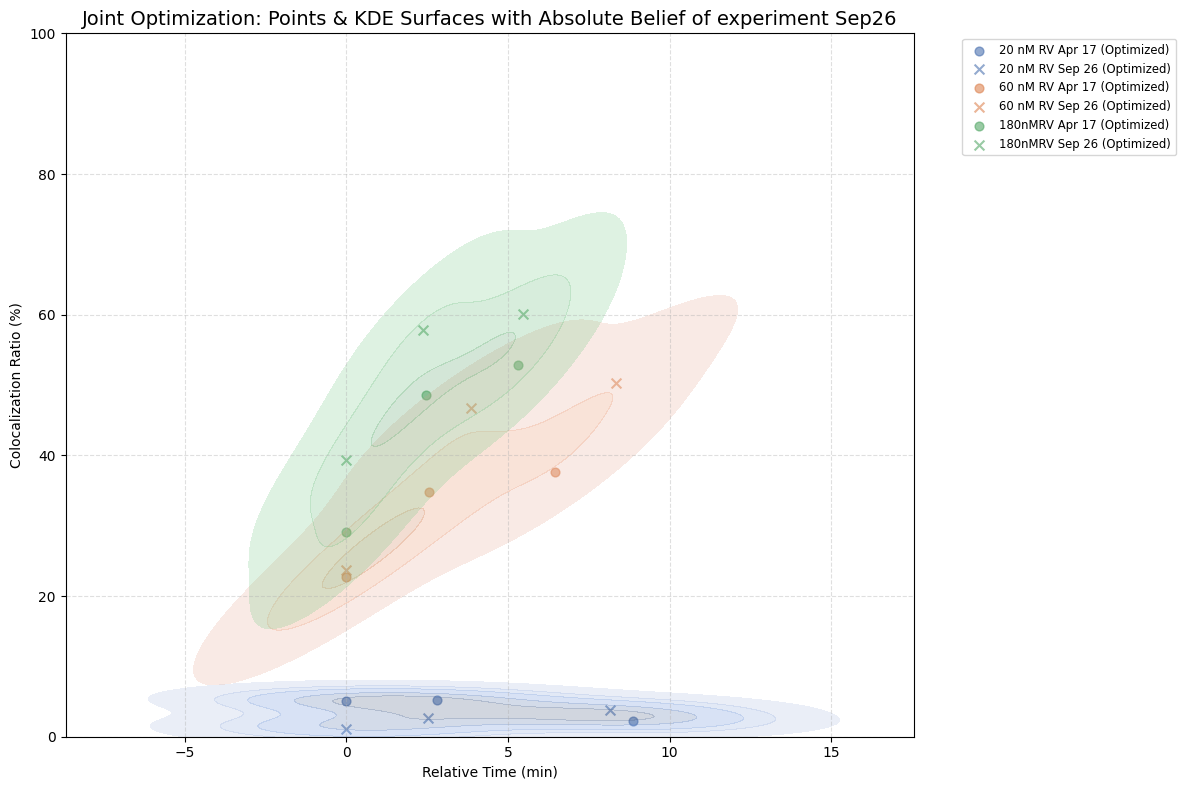

In [7]:
import pandas as pd
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns

belief_x = 100000000000

# --- 1. Data Preparation Functions ---

def calculate_relative_time(df_date):
    """Calculates relative time in minutes for each condition."""
    df_date = df_date.sort_values(by='Timestamp').reset_index(drop=True)
    min_timestamps = df_date.groupby('Condition')['Timestamp'].transform('min')
    time_diff = df_date['Timestamp'] - min_timestamps
    df_date['Relative_Time_Minutes'] = time_diff.dt.total_seconds() / 60
    return df_date

# --- 2. Shape Descriptors Function ---

def get_shape_descriptors(t, y):
    """
    Calculates slope (mu) and curvature (kappa) based on a quadratic fit.
    t is centered to decouple the terms.
    y = kappa * t_centered^2 + mu * t_centered + intercept
    """
    if len(t) < 2: return 0.0, 0.0
    t_centered = t - np.mean(t)
    
    if len(t) == 2:
        # Linear fit for only two points: coeffs = [slope, intercept]
        coeffs = np.polyfit(t_centered, y, 1)
        return coeffs[0], 0.0
    else:
        # Quadratic fit: coeffs = [curvature (kappa), slope (mu), intercept]
        coeffs = np.polyfit(t_centered, y, 2)
        return coeffs[1], coeffs[0] # Return slope (mu), curvature (kappa)

# --- 3. Joint Objective Function (The Core Math with Equal Belief) ---

def joint_objective(Y_all, N_A17, t_A17, M_A17, SD_A17, t_S26, M_S26, SD_S26):
    """
    The Loss Function (L) to minimize.
    L = L_Shape + L_Dev_A17 + L_Dev_S26
    Weighting: w_A17 = 1.0, w_S26 = 1.0 (Equal Belief)
    """
    Y_A17 = Y_all[:N_A17]
    Y_S26 = Y_all[N_A17:]
    
    # 1. Shape Mismatch Penalty (L_Shape)
    slope_A17, curv_A17 = get_shape_descriptors(t_A17, Y_A17)
    slope_S26, curv_S26 = get_shape_descriptors(t_S26, Y_S26)
    
    # High fixed weights to prioritize trend matching
    W_SLOPE = 1000.0
    W_CURV = 100.0 * W_SLOPE
    
    L_Shape = W_SLOPE * (slope_A17 - slope_S26)**2 + W_CURV * (curv_A17 - curv_S26)**2
    
    # 2. Deviation from Mean Penalties (L_Dev)
    
    # L_Dev, A17 (w_A17 = 1.0)
    # Normalized Chi-squared distance from mean
    L_Dev_A17 = 1.0 * np.sum(((Y_A17 - M_A17) / SD_A17)**2)
    
    # L_Dev, S26 (w_S26 = 1.0 - Equal Belief)
    L_Dev_S26 = belief_x * np.sum(((Y_S26 - M_S26) / SD_S26)**2)
    
    total_loss = L_Shape + L_Dev_A17 + L_Dev_S26
    return total_loss

# --- 4. Optimization Execution Function ---

def joint_optimize_trajectories(df_A17, df_S26, condition):
    
    # Prepare Data and Bounds
    data_A17 = df_A17[df_A17['Condition'] == condition].sort_values('Relative_Time_Minutes')
    data_S26 = df_S26[df_S26['Condition'] == condition].sort_values('Relative_Time_Minutes')
    
    if data_A17.empty or data_S26.empty or len(data_A17) < 2 or len(data_S26) < 2:
        return None
    
    # Extract data (Apr 17)
    t_A17, M_A17, SD_A17 = data_A17[['Relative_Time_Minutes', 'Ratio_percent', 'SD_Ratio']].values.T
    L_A17 = M_A17 - SD_A17
    U_A17 = M_A17 + SD_A17
    
    # Extract data (Sep 26)
    t_S26, M_S26, SD_S26 = data_S26[['Relative_Time_Minutes', 'Ratio_percent', 'SD_Ratio']].values.T
    L_S26 = M_S26 - SD_S26
    U_S26 = M_S26 + SD_S26
    
    # Handle zero SD for normalization
    SD_A17 = np.where(SD_A17 == 0, 1e-6, SD_A17)
    SD_S26 = np.where(SD_S26 == 0, 1e-6, SD_S26)

    # Setup Optimization Variables and Bounds
    Y_initial = np.concatenate([M_A17, M_S26])
    
    bounds_A17 = list(zip(L_A17, U_A17))
    bounds_S26 = list(zip(L_S26, U_S26))
    bounds_all = bounds_A17 + bounds_S26
    
    N_A17 = len(M_A17)
    args = (N_A17, t_A17, M_A17, SD_A17, t_S26, M_S26, SD_S26)
    
    # Perform Optimization
    result = minimize(
        joint_objective, 
        Y_initial, 
        args=args, 
        method='L-BFGS-B', 
        bounds=bounds_all
    )
    
    # Process Results
    Y_opt_all = result.x
    Y_opt_A17 = Y_opt_all[:N_A17]
    Y_opt_S26 = Y_opt_all[N_A17:]
    
    slope_A17, curv_A17 = get_shape_descriptors(t_A17, Y_opt_A17)
    slope_S26, curv_S26 = get_shape_descriptors(t_S26, Y_opt_S26)
    
    return {
        't_A17': t_A17, 'Y_A17': Y_opt_A17, 'L_A17': L_A17, 'U_A17': U_A17, 
        't_S26': t_S26, 'Y_S26': Y_opt_S26, 'L_S26': L_S26, 'U_S26': U_S26,
        'slope_A17': slope_A17, 'curv_A17': curv_A17,
        'slope_S26': slope_S26, 'curv_S26': curv_S26,
        'success': result.success
    }

# --- 5. Main Execution and Plotting ---

# --- Data Loading and Cleaning ---
df = pd.read_csv("mydata.csv", header=None, skiprows=4)
df_processed = df.iloc[:, [0, 3, 4, 7, 8, 14, 16]].copy()  # Shifted indices
df_processed.columns = ['Condition', 'Date', 'Time', 'A_i', 'n_PL1', 'k_Colocalized', 'Ratio_percent']
df_processed.dropna(axis=0, how='all', inplace=True)
df_processed['Condition'] = df_processed['Condition'].ffill()
df_processed['Date'] = df_processed['Date'].ffill()

df_processed['Ratio_percent'] = df_processed['Ratio_percent'].astype(str).str.replace('%', '', regex=False).astype(float)
df_processed['n_PL1'] = pd.to_numeric(df_processed['n_PL1'], errors='coerce')
df_processed['k_Colocalized'] = pd.to_numeric(df_processed['k_Colocalized'], errors='coerce')
df_processed.dropna(subset=['A_i', 'Ratio_percent', 'Date', 'Time', 'n_PL1', 'k_Colocalized'], inplace=True)

# Convert date format from DD/MM/YYYY to YYYY-MM-DD
df_processed['Timestamp'] = pd.to_datetime(df_processed['Date'] + ' ' + df_processed['Time'], format='%d/%m/%Y %H:%M:%S', errors='coerce')
df_processed['Date'] = df_processed['Timestamp'].dt.strftime('%Y-%m-%d')
df_processed.dropna(subset=['Timestamp'], inplace=True)

# SD Calculation (Binomial assumption)
df_processed['p'] = df_processed['Ratio_percent'] / 100
df_processed['n'] = df_processed['n_PL1']
df_processed['Var_Ratio'] = np.where(
    df_processed['n'] > 0,
    100**2 * df_processed['p'] * (1 - df_processed['p']) / df_processed['n'],
    0.0
)
df_processed['SD_Ratio'] = np.sqrt(df_processed['Var_Ratio'])

# Split and Relative Time Calculation
df_20240417 = calculate_relative_time(df_processed[df_processed['Date'] == '2024-04-17'].copy())
df_20240926 = calculate_relative_time(df_processed[df_processed['Date'] == '2024-09-26'].copy())
# --- Execute Joint Optimization ---
# --- 5. Main Execution and KDE Plotting ---

# ... [Keep your existing data loading and optimization code above] ...

# --- 5. Main Execution and Plotting (Updated for Scatter + KDE Surface) ---

# ... [Keep your existing Data Loading and Optimization code as is] ...

# --- Execute Joint Optimization ---
conditions = ['20 nM RV', '60 nM RV', '180nMRV']
joint_results = {}

for cond in conditions:
    res = joint_optimize_trajectories(df_20240417, df_20240926, cond)
    if res:
        joint_results[cond] = res

# --- NEW: Plotting Scatter Points and KDE Surfaces ---
fig, ax = plt.subplots(figsize=(12, 8))
colors = sns.color_palette('deep', len(conditions))
all_points_data = []

for i, cond in enumerate(conditions):
    res = joint_results.get(cond)
    if not res or not res['success']: 
        continue
        
    col = colors[i]
    
    # 1. Plot Scattered Points for both experiments
    # April 17: Circles
    ax.scatter(res['t_A17'], res['Y_A17'], color=col, marker='o', s=40, 
               alpha=0.6, label=f"{cond} Apr 17 (Optimized)")
    # September 26: X markers
    ax.scatter(res['t_S26'], res['Y_S26'], color=col, marker='x', s=50, 
               alpha=0.6, label=f"{cond} Sep 26 (Optimized)")
    
    # 2. Collect combined points for the KDE surface calculation
    t_combined = np.concatenate([res['t_A17'], res['t_S26']])
    y_combined = np.concatenate([res['Y_A17'], res['Y_S26']])
    
    # Store in a temporary list for Seaborn plotting
    all_points_data.append(pd.DataFrame({
        'Relative Time (min)': t_combined, 
        'Ratio (%)': y_combined, 
        'Condition': cond
    }))

# 3. Build and overlay KDE surfaces for each condition
if all_points_data:
    df_kde = pd.concat(all_points_data)
    sns.kdeplot(
        data=df_kde, 
        x='Relative Time (min)', 
        y='Ratio (%)', 
        hue='Condition', 
        fill=True,           # This creates the "surface" effect
        alpha=0.25,          # Transparency for overlapping areas
        levels=6,            # Number of contour levels
        thresh=0.05,         # Filter out very low density tails
        palette='deep', 
        ax=ax
    )

# Formatting the plot
#ax.set_title(f"Joint Optimization: Points & KDE Surfaces (Belief: {belief_x}x for Sep 26)", fontsize=14)
ax.set_title("Joint Optimization: Points & KDE Surfaces with Absolute Belief of experiment Sep26", fontsize=14)
ax.set_xlabel("Relative Time (min)")
ax.set_ylabel("Colocalization Ratio (%)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.set_ylim(0, 100) # Ensure the full ratio range is visible
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')

plt.tight_layout()
#plt.savefig(f'joint_optimized_scatter_kde_{belief_x}x.svg', format='svg')

plt.savefig('joint_optimized_scatter_kde_Absolute_Belief_of_exp_Sep26.svg', format='svg')
plt.show()

## 3 Conditions

/tmp/ipykernel_3957399/3817784585.py:35: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_plot = df_processed.groupby(['Condition', 'Date'], group_keys=False).apply(calculate_relative)


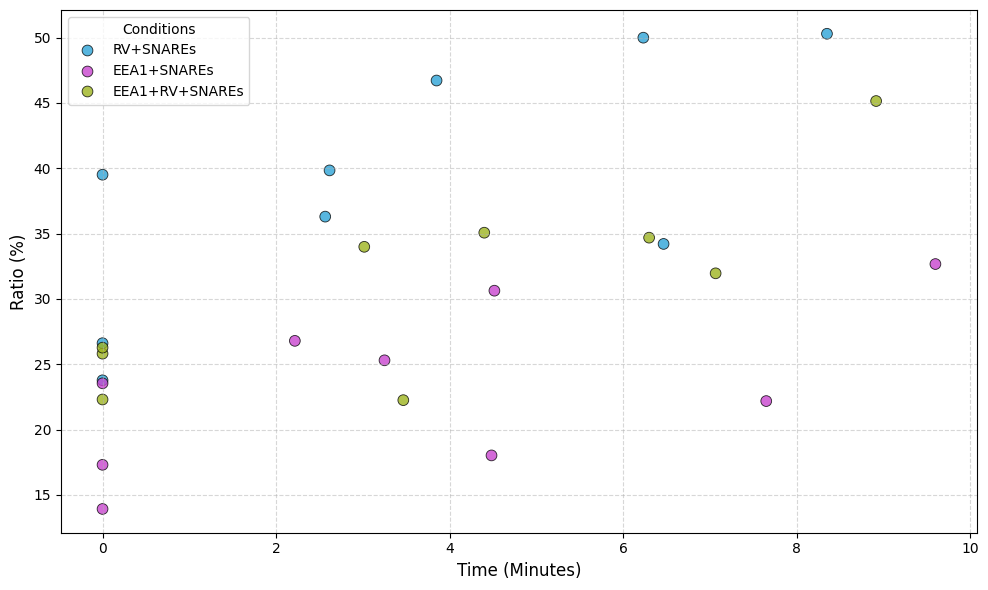

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load data
# We don't skip rows globally because 'Condition' labels are scattered
df_raw = pd.read_csv("mydata2.csv", header=None)

# 2. Extract specific columns based on your file structure
# Col 0: Condition, Col 3: Date, Col 4: Time, Col 7: Well/Channel, Col 14: Ratio
df_processed = df_raw.iloc[:, [0, 3, 4, 7, 16]].copy()
df_processed.columns = ['Condition', 'Date', 'Time', 'Channel', 'Ratio']

# 3. Cleaning
# Fill the 'Condition' and 'Date' downwards so every measurement has a label
df_processed['Condition'] = df_processed['Condition'].ffill()
df_processed['Date'] = df_processed['Date'].ffill()

# Drop rows that don't have measurement data (Ratio or Channel)
df_processed = df_processed.dropna(subset=['Channel', 'Ratio'])

# Clean Ratio string (remove % and convert to float)
df_processed['Ratio'] = df_processed['Ratio'].astype(str).str.replace('%', '').astype(float)

# Create Timestamp for time calculation
df_processed['Timestamp'] = pd.to_datetime(df_processed['Date'] + ' ' + df_processed['Time'], dayfirst=True)

# 4. Calculate Relative Time per Condition + Date group
# This ensures each trajectory starts at X=0
def calculate_relative(group):
    group = group.sort_values('Timestamp')
    group['Relative_Time'] = (group['Timestamp'] - group['Timestamp'].min()).dt.total_seconds() / 60
    return group

df_plot = df_processed.groupby(['Condition', 'Date'], group_keys=False).apply(calculate_relative)

# 5. Plotting
plt.figure(figsize=(10, 6))

# 'hue' handles the 3 colors for the 3 conditions
# 'units' ensures replicates are drawn as separate lines rather than averaged
# 'estimator=None' is required when using 'units'
# sns.lineplot(
#     data=df_plot, 
#     x='Relative_Time', 
#     y='Ratio', 
#     hue='Condition', 
#     units='Date',     # This treats each unique date/replicate as its own line
#     estimator=None,   # This prevents Seaborn from averaging the 3 points
#     marker='o',
#     markersize=8,
#     palette=["#2ea4d7", "#c845cf", "#9eb41f"], # Distinct Green, Red, Blue
#     alpha=0.8
# )
sns.scatterplot(
    data=df_plot, 
    x='Relative_Time', 
    y='Ratio', 
    hue='Condition', 
    palette=["#2ea4d7", "#c845cf", "#9eb41f"],
    s=60,
    edgecolor='black',
    alpha=0.8,
    legend=True
)
#Labeling
#plt.title('Trajectories for Experimental Conditions', fontsize=14, pad=15)
plt.xlabel('Time (Minutes)', fontsize=12)
plt.ylabel('Ratio (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Fix Legend (sns.lineplot with 'units' can sometimes duplicate legends)
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:3], labels[:3], title='Conditions')

plt.tight_layout()
#plt.show()
plt.savefig('3conditions_scatterpoints.svg', format='svg')

/tmp/ipykernel_3957399/2881613983.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_plot = df_processed.groupby(['Condition', 'Date'], group_keys=False).apply(calculate_relative)


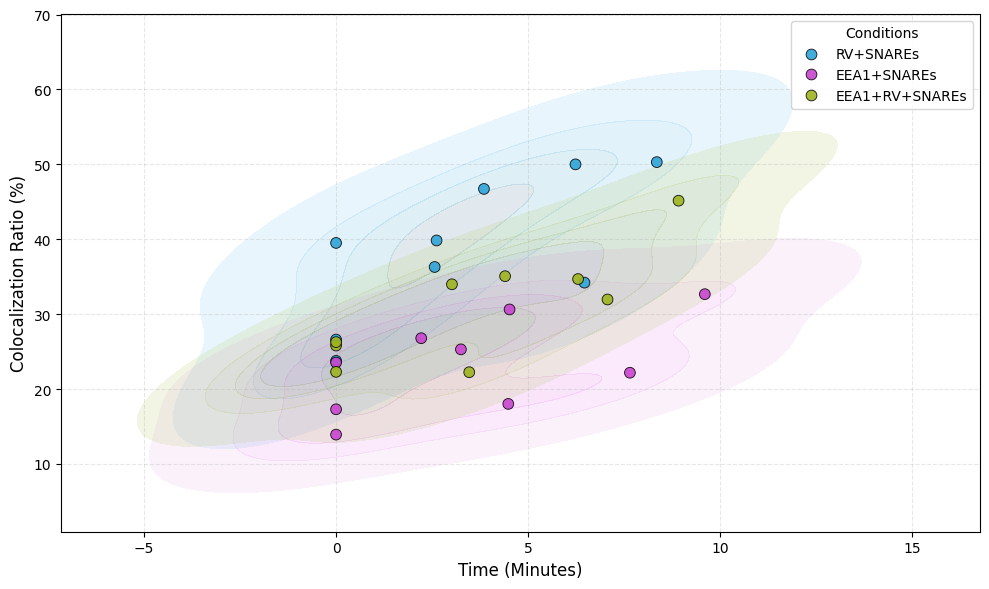

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load data
df_raw = pd.read_csv("mydata2.csv", header=None)

# 2. Extract specific columns
df_processed = df_raw.iloc[:, [0, 3, 4, 7, 16]].copy()
df_processed.columns = ['Condition', 'Date', 'Time', 'Channel', 'Ratio']

# 3. Cleaning
df_processed['Condition'] = df_processed['Condition'].ffill()
df_processed['Date'] = df_processed['Date'].ffill()
df_processed = df_processed.dropna(subset=['Channel', 'Ratio'])
df_processed['Ratio'] = df_processed['Ratio'].astype(str).str.replace('%', '').astype(float)
df_processed['Timestamp'] = pd.to_datetime(df_processed['Date'] + ' ' + df_processed['Time'], dayfirst=True)

# 4. Calculate Relative Time
def calculate_relative(group):
    group = group.sort_values('Timestamp')
    group['Relative_Time'] = (group['Timestamp'] - group['Timestamp'].min()).dt.total_seconds() / 60
    return group

df_plot = df_processed.groupby(['Condition', 'Date'], group_keys=False).apply(calculate_relative)

# 5. Plotting
plt.figure(figsize=(10, 6))
my_palette = ["#2ea4d7", "#c845cf", "#9eb41f"]

# --- ADDED: The "Cloud" layer ---
# We use kdeplot to create a shaded density area behind the points.
sns.kdeplot(
    data=df_plot,
    x='Relative_Time',
    y='Ratio',
    hue='Condition',
    palette=my_palette,
    fill=True,       # This creates the "cloud" effect
    alpha=0.15,      # Transparency of the cloud
    levels=5,        # Number of contour levels (higher = more detailed)
    thresh=0.05,     # The outer boundary of the cloud (lower = larger cloud)
    legend=True,     # Don't duplicate the legend
    zorder=1         # Ensure it stays behind the scatter points
)

# --- Scatter points on top ---
sns.scatterplot(
    data=df_plot, 
    x='Relative_Time', 
    y='Ratio', 
    hue='Condition', 
    palette=my_palette,
    s=60,
    edgecolor='black',
    alpha=0.9,
    legend=True,
    zorder=2         # Ensure points are drawn on top of the cloud
)

# Labeling
plt.xlabel('Time (Minutes)', fontsize=12)
plt.ylabel('Colocalization Ratio (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)

# Fix Legend
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:3], labels[:3], title='Conditions')

plt.tight_layout()
#plt.show()
plt.savefig('3conditions_kde.svg', format='svg')